## 1. Setup


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import re
import json
import random
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


## 2. Configuration




In [27]:
PROJECT_DIR = Path('/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים')
PROCESSED_DIR = PROJECT_DIR / "Processed_unprepared"

CLASS_NAMES = ['choking', 'laughter']
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}

INPUT_SHAPE = (20, 128, 128)
NUM_CLASSES = len(CLASS_NAMES)

BATCH_SIZE = 16
EPOCHS = 15
LR = 5e-4
WEIGHT_DECAY = 1e-3

SAVE_DIR = "/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים"

MODEL_NAME = "audio_FNN_v1"
MODEL_SAVE_PATH = os.path.join(
    SAVE_DIR,
    f"{MODEL_NAME}_best.pth"
)
RESULTS_CSV_PATH = Path('/content/fnn_baseline_results.csv')

print('Processed dir:', PROCESSED_DIR)
print('Classes:', CLASS_TO_IDX)

Processed dir: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/Processed_unprepared
Classes: {'choking': 0, 'laughter': 1}


## 3. Dataset loader


In [ ]:
AUG_SUFFIX_PATTERN = re.compile(r'(_noise|_ts0\.85|_ts1\.15|_ps-2|_ps\+2)$')

def base_name_from_path(path: Path) -> str:
    """Strip known augmentation suffixes so augmented files stay with their original."""
    stem = path.stem
    previous = None
    while previous != stem:
        previous = stem
        stem = AUG_SUFFIX_PATTERN.sub('', stem)
    return stem

class NpyAudioDataset(Dataset):
    def __init__(self, processed_dir, class_names):
        self.processed_dir = Path(processed_dir)
        self.class_names = list(class_names)
        self.class_to_idx = {c: i for i, c in enumerate(self.class_names)}
        self.samples = []

        for cls in self.class_names:
            cls_dir = self.processed_dir / cls
            if not cls_dir.exists():
                raise FileNotFoundError(f'Missing class folder: {cls_dir}')
            for path in sorted(cls_dir.glob('*.npy')):
                self.samples.append({
                    'path': path,
                    'label': self.class_to_idx[cls],
                    'class_name': cls,
                    'base_name': base_name_from_path(path),
                })

        if len(self.samples) == 0:
            raise RuntimeError(f'No .npy files found under {self.processed_dir}')

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        item = self.samples[idx]
        x = np.load(item['path']).astype(np.float32)

        if x.shape != INPUT_SHAPE:
            raise ValueError(f'Expected {INPUT_SHAPE}, got {x.shape} for {item["path"]}')

        return torch.from_numpy(x), torch.tensor(item['label'], dtype=torch.long), str(item['path'])


dataset = NpyAudioDataset(PROCESSED_DIR, CLASS_NAMES)
print('Total samples:', len(dataset))
print('Label counts:', Counter(s['class_name'] for s in dataset.samples))
print('Example:', dataset.samples[0])

Total samples: 720
Label counts: Counter({'choking': 360, 'laughter': 360})
Example: {'path': PosixPath('/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/Processed_unprepared/choking/הקלטה חדשה 2.npy'), 'label': 0, 'class_name': 'choking', 'base_name': 'הקלטה חדשה 2'}


## 4. Train / validation / test split


In [ ]:
def find_manifest(processed_dir: Path):
    candidates = [
        processed_dir / 'split_manifest.json',
        processed_dir.parent / 'split_manifest.json',
        Path('/content/split_manifest.json'),
    ]
    for c in candidates:
        if c.exists():
            return c
    return None


def split_from_manifest(dataset, manifest_path: Path):
    """
    Supports common manifest formats:
    1. {'train': [...], 'val': [...], 'test': [...]}
    2. {'splits': {'train': [...], 'val': [...], 'test': [...]}}

    Entries can be full paths or filenames/stems.
    """
    with open(manifest_path, 'r') as f:
        manifest = json.load(f)

    split_obj = manifest.get('splits', manifest)
    index_by_keys = defaultdict(list)

    for i, s in enumerate(dataset.samples):
        p = s['path']
        keys = {
            str(p),
            p.name,
            p.stem,
            f"{s['class_name']}/{p.name}",
            f"{s['class_name']}/{p.stem}",
        }
        for k in keys:
            index_by_keys[k].append(i)

    out = {}
    for split_name in ['train', 'val', 'test']:
        entries = split_obj.get(split_name, [])
        idxs = []
        for e in entries:
            if isinstance(e, dict):
                e_keys = [str(e.get('path', '')), str(e.get('file', '')), str(e.get('filename', '')), str(e.get('stem', ''))]
            else:
                e_keys = [str(e)]
            for key in e_keys:
                if key in index_by_keys:
                    idxs.extend(index_by_keys[key])
                    break
        out[split_name] = sorted(set(idxs))

    return out['train'], out['val'], out['test']


def grouped_stratified_split(dataset, seed=42):
    """Group by class + base_name, then split groups stratified by class."""
    groups = []
    group_to_indices = defaultdict(list)

    for i, s in enumerate(dataset.samples):
        key = (s['class_name'], s['base_name'])
        group_to_indices[key].append(i)

    for key, idxs in group_to_indices.items():
        cls, base = key
        groups.append({'key': key, 'class_name': cls, 'indices': idxs})

    group_labels = [CLASS_TO_IDX[g['class_name']] for g in groups]
    group_indices = np.arange(len(groups))

    train_g, temp_g = train_test_split(
        group_indices,
        test_size=0.30,
        random_state=seed,
        stratify=group_labels,
    )

    temp_labels = [group_labels[i] for i in temp_g]
    val_g, test_g = train_test_split(
        temp_g,
        test_size=0.50,
        random_state=seed,
        stratify=temp_labels,
    )

    def expand(group_ids):
        idxs = []
        for gi in group_ids:
            idxs.extend(groups[gi]['indices'])
        return sorted(idxs)

    return expand(train_g), expand(val_g), expand(test_g)


manifest_path = find_manifest(PROCESSED_DIR)
if manifest_path is not None:
    print('Using manifest:', manifest_path)
    train_idx, val_idx, test_idx = split_from_manifest(dataset, manifest_path)
    if min(len(train_idx), len(val_idx), len(test_idx)) == 0:
        print('Manifest was found but could not be matched fully. Falling back to grouped split.')
        train_idx, val_idx, test_idx = grouped_stratified_split(dataset, SEED)
else:
    print('No manifest found. Creating grouped stratified split.')
    train_idx, val_idx, test_idx = grouped_stratified_split(dataset, SEED)

print('Split sizes:', len(train_idx), len(val_idx), len(test_idx))
for name, idxs in [('train', train_idx), ('val', val_idx), ('test', test_idx)]:
    print(name, Counter(dataset.samples[i]['class_name'] for i in idxs))

No manifest found. Creating grouped stratified split.
Split sizes: 504 108 108
train Counter({'choking': 252, 'laughter': 252})
val Counter({'choking': 54, 'laughter': 54})
test Counter({'choking': 54, 'laughter': 54})


In [ ]:
train_loader = DataLoader(Subset(dataset, train_idx), batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(Subset(dataset, val_idx),   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(Subset(dataset, test_idx),  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

## 5. FNN architecture


In [ ]:
class AudioFNN(nn.Module):
    def __init__(self, input_shape=(20, 128, 128), num_classes=2):
        super().__init__()
        input_size = input_shape[0] * input_shape[1] * input_shape[2]

        self.classifier = nn.Sequential(
            nn.Flatten(),

            nn.Linear(input_size, 512),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(x)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

model = AudioFNN(INPUT_SHAPE, NUM_CLASSES).to(device)
print(model)
print('Trainable parameters:', f'{count_parameters(model):,}')

AudioFNN(
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=327680, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=512, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.4, inplace=False)
    (7): Linear(in_features=128, out_features=2, bias=True)
  )
)
Trainable parameters: 167,838,594


## 6. Training utilities

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=4)


def run_epoch(model, loader, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.set_grad_enabled(is_train):
        for x, y, _ in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            logits = model(x)
            loss = criterion(logits, y)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * x.size(0)
            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.detach().cpu().numpy())
            all_labels.extend(y.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)
    return avg_loss, acc

## 7. Train the FNN

In [ ]:
history = []
best_val_loss = float('inf')

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(model, train_loader, optimizer)
    val_loss, val_acc = run_epoch(model, val_loader, optimizer=None)
    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]['lr']

    row = {
        'epoch': epoch,
        'train_loss': train_loss,
        'train_acc': train_acc,
        'val_loss': val_loss,
        'val_acc': val_acc,
        'lr': current_lr,
    }
    history.append(row)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save({
            'model_state_dict': model.state_dict(),
            'input_shape': INPUT_SHAPE,
            'class_names': CLASS_NAMES,
            'params': count_parameters(model),
            'epoch': epoch,
            'best_val_loss': best_val_loss,
        }, MODEL_SAVE_PATH)
        best_marker = '  <-- best'
    else:
        best_marker = ''

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss {train_loss:.4f}, acc {train_acc:.3f} | "
        f"val loss {val_loss:.4f}, acc {val_acc:.3f} | "
        f"lr {current_lr:.2e}{best_marker}"
    )

history_df = pd.DataFrame(history)
history_df.to_csv(RESULTS_CSV_PATH, index=False)
history_df

Epoch 01/15 | train loss 12.3387, acc 0.524 | val loss 6.5858, acc 0.500 | lr 5.00e-04  <-- best
Epoch 02/15 | train loss 3.9308, acc 0.595 | val loss 0.6985, acc 0.630 | lr 5.00e-04  <-- best
Epoch 03/15 | train loss 2.0332, acc 0.556 | val loss 0.7882, acc 0.593 | lr 5.00e-04
Epoch 04/15 | train loss 1.0304, acc 0.641 | val loss 0.6202, acc 0.713 | lr 5.00e-04  <-- best
Epoch 05/15 | train loss 0.9076, acc 0.671 | val loss 0.7273, acc 0.639 | lr 5.00e-04
Epoch 06/15 | train loss 0.7783, acc 0.683 | val loss 0.7820, acc 0.694 | lr 5.00e-04
Epoch 07/15 | train loss 0.4921, acc 0.796 | val loss 0.6377, acc 0.769 | lr 5.00e-04
Epoch 08/15 | train loss 0.6076, acc 0.685 | val loss 0.6047, acc 0.648 | lr 5.00e-04  <-- best
Epoch 09/15 | train loss 0.5981, acc 0.669 | val loss 0.7812, acc 0.630 | lr 5.00e-04
Epoch 10/15 | train loss 0.5988, acc 0.706 | val loss 1.0100, acc 0.593 | lr 5.00e-04
Epoch 11/15 | train loss 0.6856, acc 0.629 | val loss 0.5979, acc 0.731 | lr 5.00e-04  <-- best
Epo

,epoch,train_loss,train_acc,val_loss,val_acc,lr
0,1,12.338692,0.523810,6.585767,0.500000,0.0005
1,2,3.930801,0.595238,0.698454,0.629630,0.0005
2,3,2.033216,0.555556,0.788162,0.592593,0.0005
3,4,1.030435,0.640873,0.620213,0.712963,0.0005
4,5,0.907597,0.670635,0.727254,0.638889,0.0005
5,6,0.778349,0.682540,0.782038,0.694444,0.0005
6,7,0.492060,0.795635,0.637733,0.768519,0.0005
7,8,0.607607,0.684524,0.604737,0.648148,0.0005
8,9,0.598097,0.668651,0.781172,0.629630,0.0005
9,10,0.598844,0.706349,1.009971,0.592593,0.0005


## 8. Training curves

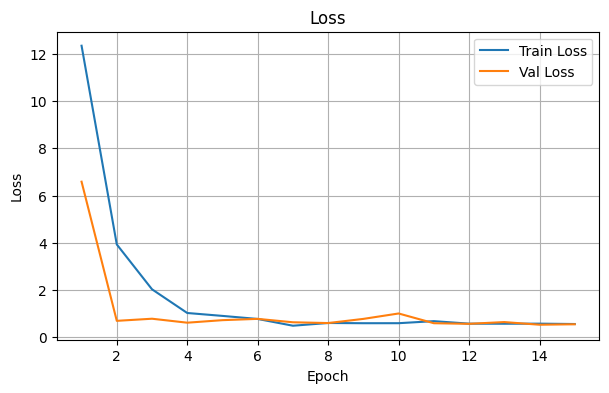

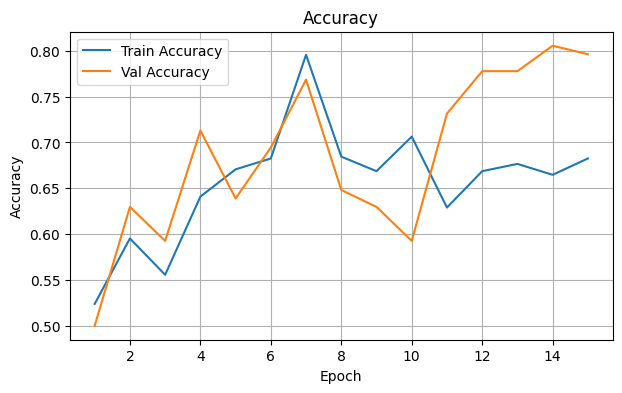

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(history_df['epoch'], history_df['train_loss'], label='Train Loss')
plt.plot(history_df['epoch'], history_df['val_loss'], label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history_df['epoch'], history_df['train_acc'], label='Train Accuracy')
plt.plot(history_df['epoch'], history_df['val_acc'], label='Val Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

## 9. Test evaluation

In [30]:
import os
import torch

SAVE_DIR = "/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים"
os.makedirs(SAVE_DIR, exist_ok=True)

MODEL_SAVE_PATH = os.path.join(SAVE_DIR, "audio_FNN_v1_best.pth")

torch.save({
    'model_state_dict': model.state_dict(),
    'input_shape': INPUT_SHAPE,
    'class_names': CLASS_NAMES,
    'params': count_parameters(model),
    'epoch': epoch if 'epoch' in globals() else None,
}, MODEL_SAVE_PATH)

print("Saved model to:", MODEL_SAVE_PATH)

checkpoint = torch.load(MODEL_SAVE_PATH, map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

all_preds = []
all_labels = []
all_paths = []

with torch.no_grad():
    for x, y, paths in test_loader:
        x = x.to(device, non_blocking=True)
        logits = model(x)
        preds = torch.argmax(logits, dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(y.numpy())
        all_paths.extend(paths)

print('Best epoch:', checkpoint['epoch'])
print('Parameter count:', f"{checkpoint['params']:,}")

print('\nClassification report:')
print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(all_labels, all_preds)
print('\nConfusion matrix:')
print(cm)

Saved model to: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/audio_FNN_v1_best.pth
Best epoch: 15
Parameter count: 167,838,594

Classification report:
              precision    recall  f1-score   support

     choking     0.5789    0.6111    0.5946        54
    laughter     0.5882    0.5556    0.5714        54

    accuracy                         0.5833       108
   macro avg     0.5836    0.5833    0.5830       108
weighted avg     0.5836    0.5833    0.5830       108


Confusion matrix:
[[33 21]
 [24 30]]


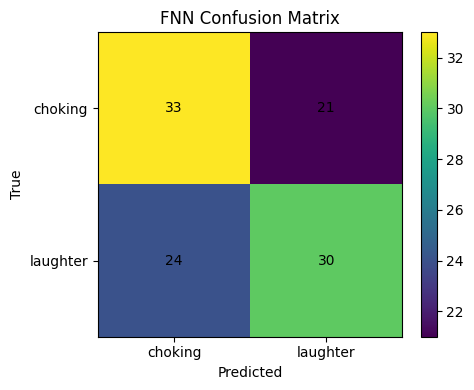

In [ ]:
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title('FNN Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.xticks(range(NUM_CLASSES), CLASS_NAMES)
plt.yticks(range(NUM_CLASSES), CLASS_NAMES)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.tight_layout()
plt.show()